# Project #23G — Fisher's Fundamental Theorem of Natural Selection
### What does "mean fitness always increases under selection" actually mean, exactly?

**Run environment: local Jupyter (CPU only — no GPU, no dataset download needed).**

**What this notebook does:** builds a discrete-generation, single-locus, multi-allele haploid selection model. Derives and confirms an exact discrete-generation form of Fisher's Fundamental Theorem (`Delta_W_bar = Var(w)/W_bar`, exactly, under constant fitness). Then extends to frequency-dependent fitness and confirms an exact two-term decomposition of the *total* change in mean fitness into the Fisher/selection term and a second "fitness values changed" term — the real, historically important distinction (clarified by George Price in 1972) between what Fisher's theorem actually proves and the popular (and false in general) reading of it as "fitness never decreases."

**Read `PROJECT_NARRATIVE.md` first, then `WORKFLOW.md`, before doing this build.**

## Step 0 — Environment setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)

numpy: 2.4.6


## Step 1 — The multi-allele selection model

**Biological reason:** a single haploid locus with `n` alleles, frequencies `p_i` (summing to 1) and fitnesses `w_i`. Each generation, natural selection reweights frequencies toward fitter alleles: the standard discrete-generation update is `p_i' = p_i*w_i / W_bar` where `W_bar = sum(p_i*w_i)` is the population's mean fitness.

In [2]:
def selection_update(p, w):
    Wbar = np.sum(p*w)
    p_next = p*w/Wbar
    return p_next, Wbar

def mean_fitness(p, w):
    return np.sum(p*w)

def variance_fitness(p, w):
    Wbar = mean_fitness(p,w)
    return np.sum(p*(w-Wbar)**2)

rng = np.random.default_rng(0)
w_const = np.array([1.0, 1.1, 0.9, 1.05])
p0 = np.array([0.25, 0.25, 0.25, 0.25])

p1, Wbar0 = selection_update(p0, w_const)
print("p0:", p0)
print("p1:", p1)
print("Wbar0:", Wbar0)
print("sum p1 (should be 1.0):", np.sum(p1))

p0: [0.25 0.25 0.25 0.25]
p1: [0.2469 0.2716 0.2222 0.2593]
Wbar0: 1.0125
sum p1 (should be 1.0): 1.0


## Step 2 — The exact constant-fitness identity

**Mathematical reason:** when fitness values `w_i` stay fixed across one generation, direct algebra on the selection update gives `W_bar' = E[w^2]/E[w]`, so **`Delta_W_bar = W_bar' - W_bar = Var(w) / W_bar`, exactly** — this is the discrete-generation form of Fisher's Fundamental Theorem: the increase in mean fitness due to selection equals the genetic variance in fitness divided by mean fitness, not approximately.

In [3]:
def fisher_check_constant(p, w):
    p_next, Wbar = selection_update(p,w)
    Wbar_next = mean_fitness(p_next, w)
    delta_Wbar_sim = Wbar_next - Wbar
    var_w = variance_fitness(p,w)
    delta_Wbar_pred = var_w/Wbar
    return delta_Wbar_sim, delta_Wbar_pred, var_w, Wbar

delta_sim, delta_pred, var_w0, Wbar0_check = fisher_check_constant(p0, w_const)
print(f"Simulated Delta W_bar:        {delta_sim:.10f}")
print(f"Fisher-predicted Var(w)/Wbar: {delta_pred:.10f}")
print(f"Exact match (should be ~0):   {abs(delta_sim - delta_pred):.2e}")
print(f"Var(w) = {var_w0:.6f}   W_bar = {Wbar0_check:.6f}")

Simulated Delta W_bar:        0.0054012346
Fisher-predicted Var(w)/Wbar: 0.0054012346
Exact match (should be ~0):   7.55e-17
Var(w) = 0.005469   W_bar = 1.012500


## Step 3 — Multi-generation simulation under constant fitness

In [4]:
def simulate_constant(p0, w, n_gen):
    p = p0.copy()
    Wbar_trace = [mean_fitness(p,w)]
    for _ in range(n_gen):
        p, _ = selection_update(p,w)
        Wbar_trace.append(mean_fitness(p,w))
    return np.array(Wbar_trace), p

Wbar_trace_const, p_final_const = simulate_constant(p0, w_const, 50)
print("W_bar trace (first 5):", Wbar_trace_const[:5])
print("W_bar trace (last 5):", Wbar_trace_const[-5:])
print("final frequencies:", p_final_const)
print("non-decreasing everywhere:", np.all(np.diff(Wbar_trace_const) >= -1e-12))

W_bar trace (first 5): [1.0125 1.0179 1.0231 1.028  1.0327]
W_bar trace (last 5): [1.0937 1.094  1.0943 1.0945 1.0948]
final frequencies: [0.0077 0.904  0.     0.0883]
non-decreasing everywhere: True


## Step 4 — Frequency-dependent fitness and the exact two-term decomposition

**Mathematical reason:** if fitness itself changes between generations (`w` becomes `w'`, e.g. because fitness is frequency-dependent and frequency just changed), the real *total* change in mean fitness is `W_bar(p',w') - W_bar(p,w)`, which is **not** just `Var(w)/W_bar` — adding and subtracting `W_bar(p',w)` gives the exact decomposition `Delta_W_bar_total = Var(w)/W_bar + sum(p_i'*(w_i'-w_i))`. The first term is Fisher's theorem (the part due to selection alone, fitness held fixed); the second term is the part Fisher's original theorem does not describe, capturing the change in the fitness values themselves.

In [5]:
def fitness_fd(p, base, alpha):
    w = base - alpha*p
    return w

def decompose_one_gen(p, base, alpha):
    w = fitness_fd(p, base, alpha)
    p_next, Wbar = selection_update(p,w)
    w_next = fitness_fd(p_next, base, alpha)

    var_w = variance_fitness(p,w)
    selection_term = var_w / Wbar

    fitness_change_term = np.sum(p_next*(w_next - w))

    Wbar_next_real = mean_fitness(p_next, w_next)
    delta_Wbar_total_real = Wbar_next_real - Wbar

    delta_Wbar_pred = selection_term + fitness_change_term

    return delta_Wbar_total_real, delta_Wbar_pred, selection_term, fitness_change_term

base = np.array([0.98, 1.00, 1.02, 1.00])
alpha_test = 0.3
p_test = np.array([0.1, 0.5, 0.1, 0.3])

real, pred, sel_term, fd_term = decompose_one_gen(p_test, base, alpha_test)
print(f"Real total Delta W_bar:       {real:.10f}")
print(f"Predicted (selection + fd):   {pred:.10f}")
print(f"Exact match (should be ~0):   {abs(real - pred):.2e}")
print(f"Selection term: {sel_term:.6f}   FD term: {fd_term:.6f}")

Real total Delta W_bar:       0.0047872871
Predicted (selection + fd):   0.0047872871
Exact match (should be ~0):   6.59e-17
Selection term: 0.002552   FD term: 0.002236


## Step 5 — Multi-generation simulation under frequency-dependent selection

In [6]:
def simulate_fd(p0, base, alpha, n_gen):
    p = p0.copy()
    total_trace = []
    sel_trace = []
    fd_trace = []
    for _ in range(n_gen):
        real, pred, sel_term, fd_term = decompose_one_gen(p, base, alpha)
        total_trace.append(real)
        sel_trace.append(sel_term)
        fd_trace.append(fd_term)
        w = fitness_fd(p, base, alpha)
        p, _ = selection_update(p,w)
    return np.array(total_trace), np.array(sel_trace), np.array(fd_trace), p

total_tr, sel_tr, fd_tr, p_final_fd = simulate_fd(p0, base, 0.3, 400)
print("Final frequencies (FD, alpha=0.3):", p_final_fd)
print("Last 5 total Delta W_bar:    ", total_tr[-5:])
print("Last 5 selection term:      ", sel_tr[-5:])
print("Last 5 FD term:             ", fd_tr[-5:])
print("Alleles still present (p>1e-3):", np.sum(p_final_fd > 1e-3))
print("Total change vanishes at equilibrium:        ", abs(total_tr[-1]) < 1e-6)

Final frequencies (FD, alpha=0.3): [0.1833 0.25   0.3167 0.25  ]
Last 5 total Delta W_bar:     [-0. -0. -0. -0.  0.]
Last 5 selection term:       [0. 0. 0. 0. 0.]
Last 5 FD term:              [-0. -0. -0. -0. -0.]
Alleles still present (p>1e-3): 4
Total change vanishes at equilibrium:         True


## Step 6 — Two different ways mean fitness can stop increasing

In [7]:
Wbar_trace_const2, p_final_const2 = simulate_constant(p0, w_const, 200)
total_tr2, sel_tr2, fd_tr2, p_final_fd2 = simulate_fd(p0, base, 0.3, 200)

print("=== Constant-fitness case ===")
print("Final frequencies:", p_final_const2)
print("Final Var(w):", variance_fitness(p_final_const2, w_const))
print("Alleles still present (p>1e-3):", np.sum(p_final_const2 > 1e-3))
print("-> Var(w) -> 0 here because selection has driven extinction of all but the fittest allele.")

print("\n=== Frequency-dependent case ===")
print("Final frequencies:", p_final_fd2)
final_w_fd = fitness_fd(p_final_fd2, base, 0.3)
print("Final Var(w):", variance_fitness(p_final_fd2, final_w_fd))
print("Alleles still present (p>1e-3):", np.sum(p_final_fd2 > 1e-3))
print("-> Var(w) -> 0 here too, but with every allele still present: frequency-dependence has")
print("   equalized realized fitness across all surviving alleles, instead of eliminating any of them.")

=== Constant-fitness case ===
Final frequencies: [0.     0.9999 0.     0.0001]
Final Var(w): 2.276586445965156e-07
Alleles still present (p>1e-3): 1
-> Var(w) -> 0 here because selection has driven extinction of all but the fittest allele.

=== Frequency-dependent case ===
Final frequencies: [0.1833 0.25   0.3167 0.25  ]
Final Var(w): 1.4748085479738376e-16
Alleles still present (p>1e-3): 4
-> Var(w) -> 0 here too, but with every allele still present: frequency-dependence has
   equalized realized fitness across all surviving alleles, instead of eliminating any of them.


## Step 7 — Does the strength of frequency dependence decide whether a full polymorphism survives?

In [8]:
alphas = [0.0, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.4, 0.8]
sweep_rows = []
for a in alphas:
    if a == 0.0:
        Wbar_trace_a, p_final_a = simulate_constant(p0, base, 400)
    else:
        total_tr_a, sel_tr_a, fd_tr_a, p_final_a = simulate_fd(p0, base, a, 400)
    n_surviving = np.sum(p_final_a > 1e-4)
    sweep_rows.append({"alpha": a, "p_final": p_final_a.copy(), "n_surviving": n_surviving})
    print(f"alpha={a:.2f}  final p={np.round(p_final_a,4)}  n_surviving={n_surviving}")

sweep_df = pd.DataFrame([{"alpha": r["alpha"], "n_surviving": r["n_surviving"],
                           **{f"p{i}_final": r["p_final"][i] for i in range(len(r["p_final"]))}}
                          for r in sweep_rows])

alpha=0.00  final p=[0.     0.0004 0.9993 0.0004]  n_surviving=3
alpha=0.02  final p=[0.     0.0468 0.9065 0.0468]  n_surviving=3
alpha=0.05  final p=[0.0017 0.1992 0.5998 0.1992]  n_surviving=4
alpha=0.08  final p=[0.022  0.2425 0.493  0.2425]  n_surviving=4
alpha=0.10  final p=[0.0534 0.2488 0.449  0.2488]  n_surviving=4
alpha=0.15  final p=[0.1167 0.25   0.3833 0.25  ]  n_surviving=4
alpha=0.20  final p=[0.15 0.25 0.35 0.25]  n_surviving=4
alpha=0.40  final p=[0.2  0.25 0.3  0.25]  n_surviving=4
alpha=0.80  final p=[0.225 0.25  0.275 0.25 ]  n_surviving=4


## Step 8 — Hero figures + CSV export

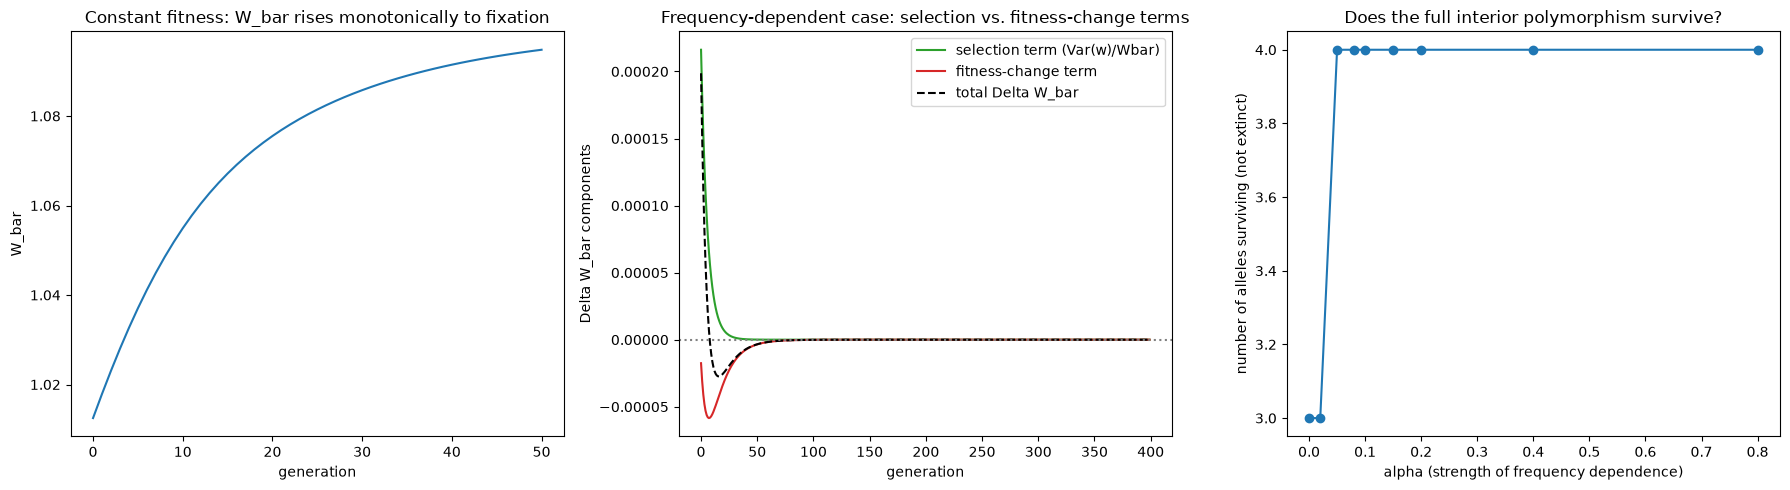

Exported results/hero_fisher_theorem.png, results/constant_fitness_trace.csv,
results/fd_decomposition_trace.csv, results/alpha_sweep.csv


In [10]:
import os
os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(Wbar_trace_const, color="tab:blue")
axes[0].set_xlabel("generation")
axes[0].set_ylabel("W_bar")
axes[0].set_title("Constant fitness: W_bar rises monotonically to fixation")

gens = np.arange(len(total_tr))
axes[1].plot(gens, sel_tr, label="selection term (Var(w)/Wbar)", color="tab:green")
axes[1].plot(gens, fd_tr, label="fitness-change term", color="tab:red")
axes[1].plot(gens, total_tr, label="total Delta W_bar", color="black", linestyle="--")
axes[1].axhline(0, color="gray", linestyle=":")
axes[1].set_xlabel("generation")
axes[1].set_ylabel("Delta W_bar components")
axes[1].set_title("Frequency-dependent case: selection vs. fitness-change terms")
axes[1].legend()

n_surviving_arr = sweep_df["n_surviving"].values
axes[2].plot(sweep_df["alpha"], n_surviving_arr, marker="o")
axes[2].set_xlabel("alpha (strength of frequency dependence)")
axes[2].set_ylabel("number of alleles surviving (not extinct)")
axes[2].set_title("Does the full interior polymorphism survive?")

plt.tight_layout()
plt.savefig("results/hero_fisher_theorem.png", dpi=150)
plt.show()

pd.DataFrame({"generation": np.arange(len(Wbar_trace_const)), "Wbar": Wbar_trace_const}).to_csv(
    "results/constant_fitness_trace.csv", index=False)
pd.DataFrame({"generation": gens, "selection_term": sel_tr, "fd_term": fd_tr,
              "total_delta_Wbar": total_tr}).to_csv("results/fd_decomposition_trace.csv", index=False)
sweep_df.to_csv("results/alpha_sweep.csv", index=False)
print("Exported results/hero_fisher_theorem.png, results/constant_fitness_trace.csv,")
print("results/fd_decomposition_trace.csv, results/alpha_sweep.csv")